## 실험 1. REINFORCE with Baseline — 초기 보상 조건

**실험 조건**:

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 2개

행동 종류: 5개

주문 타이머: 4~8스텝

정답 서빙 보상: +20

타임아웃 페널티: -10

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -52.80 | Avg Reward (50): -40.81 | Success: 0 | Timeout: 2 | Value Loss: 677.8998
Episode [100/2000] | Total Reward: -30.80 | Avg Reward (50): -33.57 | Success: 0 | Timeout: 2 | Value Loss: 17.7304
Episode [150/2000] | Total Reward: -26.70 | Avg Reward (50): -30.34 | Success: 0 | Timeout: 2 | Value Loss: 12.2883
Episode [200/2000] | Total Reward: -24.80 | Avg Reward (50): -27.75 | Success: 0 | Timeout: 2 | Value Loss: 8.7589
Episode [250/2000] | Total Reward: -24.80 | Avg Reward (50): -27.32 | Success: 0 | Timeout: 2 | Value Loss: 24.7008
Episode [300/2000] | Total Reward: -20.70 | Avg Reward (50): -23.69 | Success: 0 | Timeout: 2 | Value Loss: 17.1586
Episode [350/2000] | Total Reward: -20.50 | Avg Reward (50): -21.41 | Success: 0 | Timeout: 2 | Value Loss: 4.0591
Episode [400/2000] | Total Reward: -22.70 | Avg Reward (50): -21.01 | Success: 0 | Timeout: 2 | Value Loss: 0.8586
Episode [450/2000] | Total Reward: -20.60 | Avg Reward (50): -21.08 | Succe

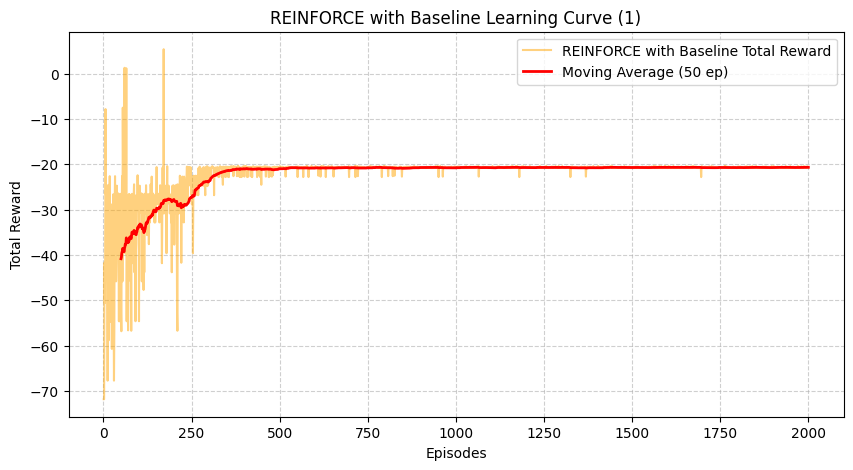

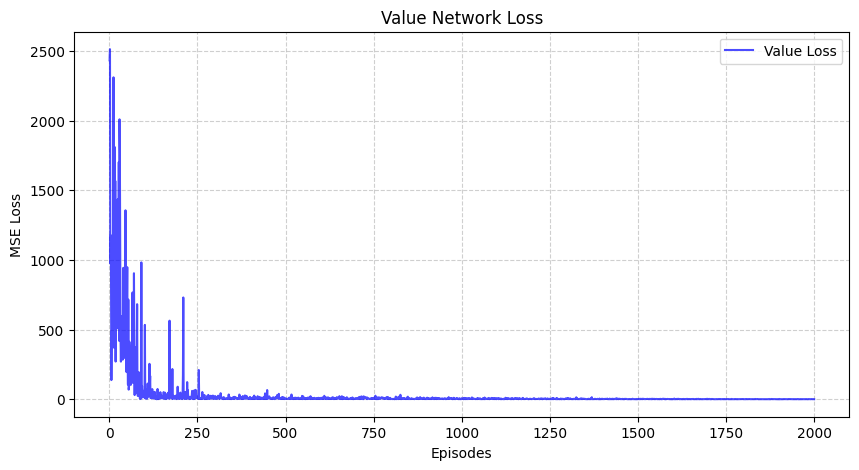

=== All 2000 Episodes ===
Idle           :  11985 (88.45%)
Add Dough      :    623 (4.60%)
Add Cheese     :    437 (3.23%)
Add Pepperoni  :    404 (2.98%)
Serve          :    101 (0.75%)

=== Last 100 Episodes ===
Idle           :    656 (100.00%)
Add Dough      :      0 (0.00%)
Add Cheese     :      0 (0.00%)
Add Pepperoni  :      0 (0.00%)
Serve          :      0 (0.00%)

=== Last 100 Episodes Performance ===
Average Reward: -20.66
Successful Orders: 0
Timed-out Orders: 200
Success Rate: 0.00%
Timeout Rate: 100.00%


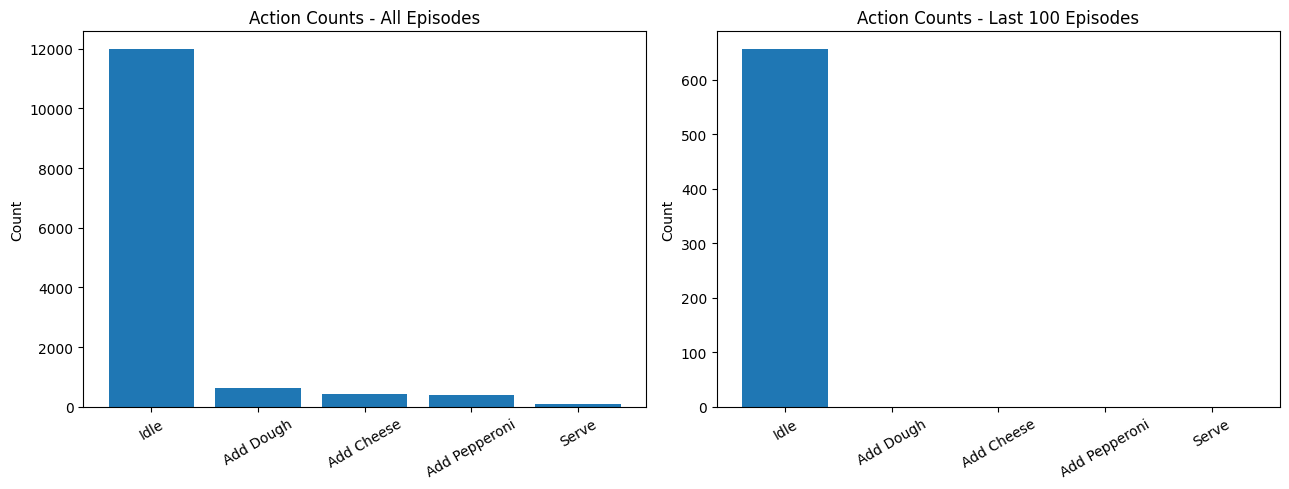

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=np.zeros(7, dtype=np.float32),
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(4, 9))
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 10.0
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                f"Episode [{episode+1}/{num_episodes}] | "
                f"Total Reward: {total_reward:.2f} | "
                f"Avg Reward (50): {avg_reward:.2f} | "
                f"Success: {success_count} | "
                f"Timeout: {timeout_count} | "
                f"Value Loss: {value_loss.item():.4f}"
            )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (1)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

초기 보상 체계에서 REINFORCE with Baseline을 2,000 에피소드 동안 학습한 결과, 초기에는 보상 변동이 크게 나타났으나 학습이 진행될수록 평균 보상이 약 -20.7점 부근에 수렴함. 마지막 50개 에피소드의 평균 보상은 -20.66점을 기록함.

행동별 선택 횟수를 분석한 결과, 전체 학습 과정에서는 Idle 행동이 가장 높은 비중을 차지하였으며, 마지막 100개 에피소드에서는 Idle 행동만 선택하는 현상이 관찰됨. 이 구간에서 성공 서빙률은 0%, 타임아웃률은 100%를 기록함.

한편 Value Network의 손실은 초기에는 큰 변동을 보였으나 학습이 진행되면서 전반적으로 감소하였으며, 마지막 2,000번째 에피소드의 Value Loss는 0.0655를 기록함.

**원인 분석**:

에이전트가 초기 탐색 과정에서 성공적인 피자 제작 경로를 충분히 발견하지 못하면서, 잘못된 재료 조작(-2)이나 잘못된 서빙(-15)에 따른 추가 감점을 회피하는 방향으로 정책이 학습된 것으로 해석됨.

실제로 마지막 100개 에피소드에서 Idle 행동 선택률이 100%로 나타났으며, 이는 에이전트가 피자 제작을 시도하는 대신 주문이 시간 초과될 때까지 대기하는 정책에 수렴했음을 보여줌.

또한 Value Network는 현재 정책에서 발생하는 누적 보상을 예측하도록 학습되어 손실이 감소하였으나, 이러한 가치 예측 성능의 향상이 성공적인 피자 제작 행동의 학습으로 이어지지는 못함.

**결론 및 시사점**:

REINFORCE with Baseline을 적용한 결과, Value Network의 예측 손실은 감소하였으나 최종 평균 보상에서는 기본 REINFORCE 대비 뚜렷한 개선이 나타나지 않음.

특히 마지막 100개 에피소드에서 Idle 행동 선택률 100%, 성공률 0%, 타임아웃률 100%가 관찰되어, 에이전트가 성공적인 피자 제작보다 추가적인 행동 페널티를 회피하는 소극적인 정책에 수렴했음을 확인함.

이는 상태 가치 함수(Value Function)를 활용한 Baseline을 추가하더라도, 성공적인 행동 경로를 충분히 탐색하지 못하는 문제는 여전히 남을 수 있음을 시사함.

따라서 다음 실험에서는 타임아웃 페널티를 -10에서 -50으로 강화하고, 동일한 REINFORCE with Baseline 구조에서 보상 조건 변화가 행동 선택과 학습 성능에 미치는 영향을 비교, 분석하고자 함.

####
## 실험 2. REINFORCE with Baseline — 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (Reward 타임아웃 페널티 -50으로 변경)

**실험 조건**:

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 2개

행동 종류: 5개

주문 타이머: 4~8스텝

정답 서빙 보상: +20

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -132.80 | Avg Reward (50): -122.19 | Success: 0 | Timeout: 2 | Value Loss: 9511.1191
Episode [100/2000] | Total Reward: -110.80 | Avg Reward (50): -116.75 | Success: 0 | Timeout: 2 | Value Loss: 2032.4591
Episode [150/2000] | Total Reward: -110.70 | Avg Reward (50): -115.02 | Success: 0 | Timeout: 2 | Value Loss: 562.6979
Episode [200/2000] | Total Reward: -36.70 | Avg Reward (50): -110.57 | Success: 1 | Timeout: 1 | Value Loss: 6205.4263
Episode [250/2000] | Total Reward: -36.80 | Avg Reward (50): -109.92 | Success: 1 | Timeout: 1 | Value Loss: 7555.5698
Episode [300/2000] | Total Reward: -104.70 | Avg Reward (50): -110.63 | Success: 0 | Timeout: 2 | Value Loss: 455.2989
Episode [350/2000] | Total Reward: -108.50 | Avg Reward (50): -111.25 | Success: 0 | Timeout: 2 | Value Loss: 82.7709
Episode [400/2000] | Total Reward: -108.70 | Avg Reward (50): -109.05 | Success: 0 | Timeout: 2 | Value Loss: 18.2120
Episode [450/2000] | Total Reward: -134.60 | Avg 

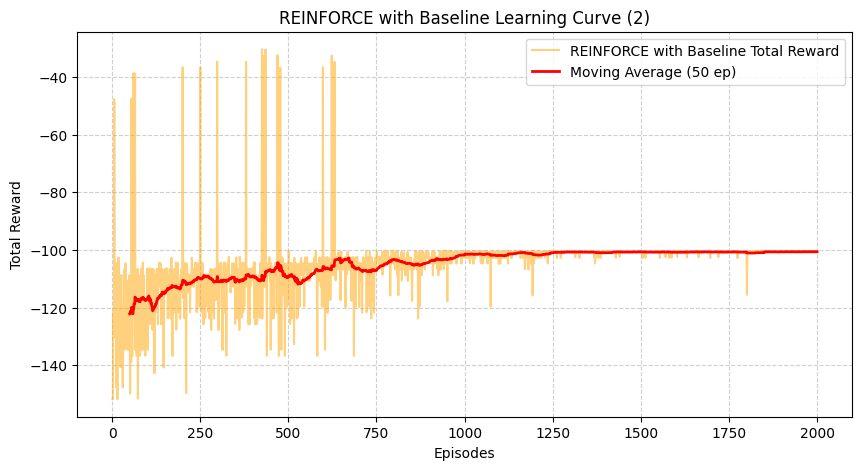

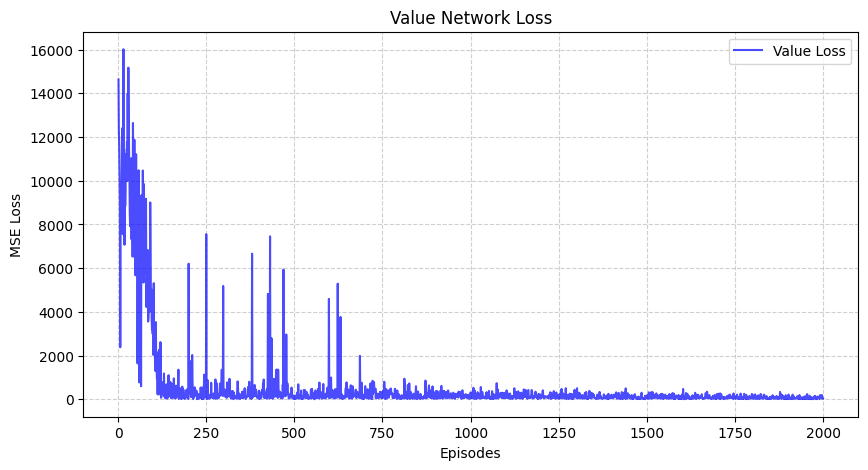

=== All 2000 Episodes ===
Idle           :   8992 (66.39%)
Add Dough      :   1446 (10.68%)
Add Cheese     :   1156 (8.53%)
Add Pepperoni  :   1681 (12.41%)
Serve          :    270 (1.99%)

=== Last 100 Episodes ===
Idle           :    655 (99.85%)
Add Dough      :      1 (0.15%)
Add Cheese     :      0 (0.00%)
Add Pepperoni  :      0 (0.00%)
Serve          :      0 (0.00%)

=== Last 100 Episodes Performance ===
Average Reward: -100.66
Successful Orders: 0
Timed-out Orders: 200
Success Rate: 0.00%
Timeout Rate: 100.00%


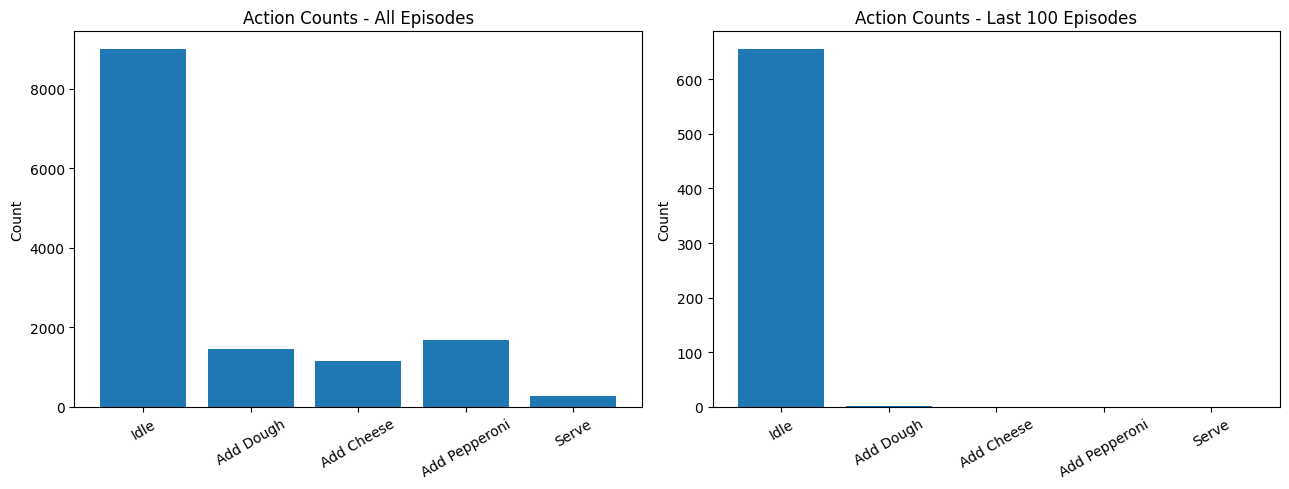

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=np.zeros(7, dtype=np.float32),
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(4, 9))
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                f"Episode [{episode+1}/{num_episodes}] | "
                f"Total Reward: {total_reward:.2f} | "
                f"Avg Reward (50): {avg_reward:.2f} | "
                f"Success: {success_count} | "
                f"Timeout: {timeout_count} | "
                f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (2)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

타임아웃 페널티를 -10에서 -50으로 강화하여 REINFORCE with Baseline을 2,000 에피소드 동안 학습한 결과, 초기에는 보상 변동이 크게 나타났으나 학습이 진행될수록 평균 보상이 약 -100점 부근에 수렴함. 마지막 100개 에피소드의 평균 보상은 -100.66점을 기록함.

행동 분석 결과, 마지막 100개 에피소드에서 Idle 행동 선택률은 99.85%, 성공 서빙률은 0%, 타임아웃률은 100%로 나타남.

한편 학습 중간인 200번째와 250번째 에피소드에서는 각각 1개의 주문을 성공적으로 서빙한 사례가 관찰되었으나, 이러한 성공이 학습 후반까지 유지되지는 못함.

Value Network의 손실은 초기의 높은 수준에서 전반적으로 감소하였으며, 마지막 에피소드의 Value Loss는 32.8377을 기록함.

**원인 분석**:

타임아웃 페널티를 강화했음에도 에이전트는 성공적인 피자 제작 정책을 안정적으로 학습하지 못하고, 학습 후반에 Idle 행동을 반복하는 정책으로 수렴함.

학습 중간에 일부 성공 사례가 관찰되었다는 점에서 성공 경로의 탐색이 완전히 이루어지지 않은 것은 아니지만, 해당 경험이 지속적인 정책 개선으로 연결되지는 못한 것으로 해석됨.

이는 엄격한 행동 순서 제약과 희소 보상으로 인해 성공적인 행동 경로를 반복적으로 경험하기 어렵고, Monte Carlo Return에 기반한 정책 업데이트 과정에서 학습 신호의 변동성이 크게 나타났기 때문일 가능성이 있음.

또한 Value Network의 손실이 전반적으로 감소했음에도 실제 서빙 성능은 개선되지 않아, 상태 가치 예측의 학습만으로는 탐색 및 정책 개선 문제를 충분히 해결하지 못했음을 보여줌.

**결론 및 시사점**:

타임아웃 페널티를 -50으로 강화한 결과, REINFORCE with Baseline은 학습 중간에 일부 성공적인 서빙을 경험했으나, 최종적으로는 평균 보상 약 -100점과 Idle 행동 선택률 99.85%에 수렴함.

이는 타임아웃에 대한 부정적 보상을 강화하는 것만으로는 에이전트의 적극적인 피자 제작 행동을 안정적으로 유도하기 어렵다는 점을 보여줌.

따라서 다음 실험에서는 정답 서빙 보상을 +20에서 +150으로 상향하여 성공 보상의 확대가 학습 성능과 행동 선택에 미치는 영향을 분석하고자 함.

####
## 실험 3. REINFORCE with Baseline - 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (정확한 피자 서빙 Reward +150으로 향상)
**실험 조건**:

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 2개

행동 종류: 5개

주문 타이머: 4~8스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -132.80 | Avg Reward (50): -119.47 | Success: 0 | Timeout: 2 | Value Loss: 9601.4277
Episode [100/2000] | Total Reward: -110.80 | Avg Reward (50): -102.53 | Success: 0 | Timeout: 2 | Value Loss: 3500.8340
Episode [150/2000] | Total Reward: -121.70 | Avg Reward (50): -116.64 | Success: 0 | Timeout: 2 | Value Loss: 153.8679
Episode [200/2000] | Total Reward: 93.30 | Avg Reward (50): -110.83 | Success: 1 | Timeout: 1 | Value Loss: 41764.5547
Episode [250/2000] | Total Reward: 93.20 | Avg Reward (50): -109.02 | Success: 1 | Timeout: 1 | Value Loss: 41549.9727
Episode [300/2000] | Total Reward: -106.70 | Avg Reward (50): -109.71 | Success: 0 | Timeout: 2 | Value Loss: 351.2053
Episode [350/2000] | Total Reward: -108.50 | Avg Reward (50): -101.11 | Success: 0 | Timeout: 2 | Value Loss: 353.0495
Episode [400/2000] | Total Reward: -108.70 | Avg Reward (50): -101.31 | Success: 0 | Timeout: 2 | Value Loss: 142.4604
Episode [450/2000] | Total Reward: -134.60 | Av

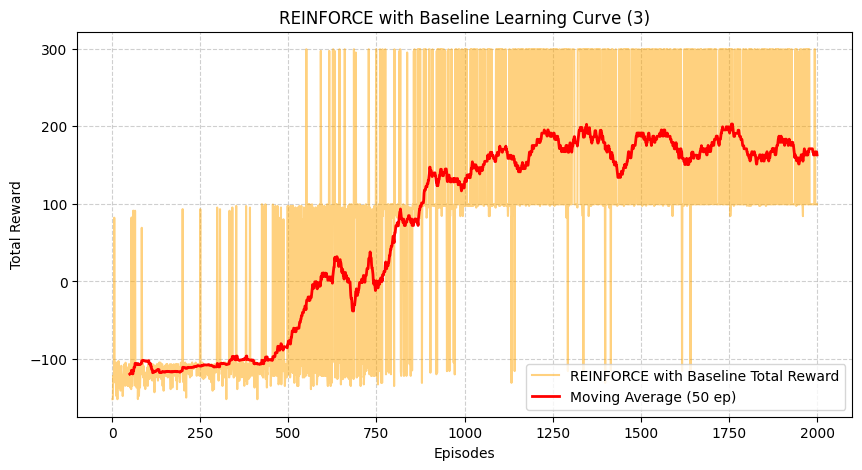

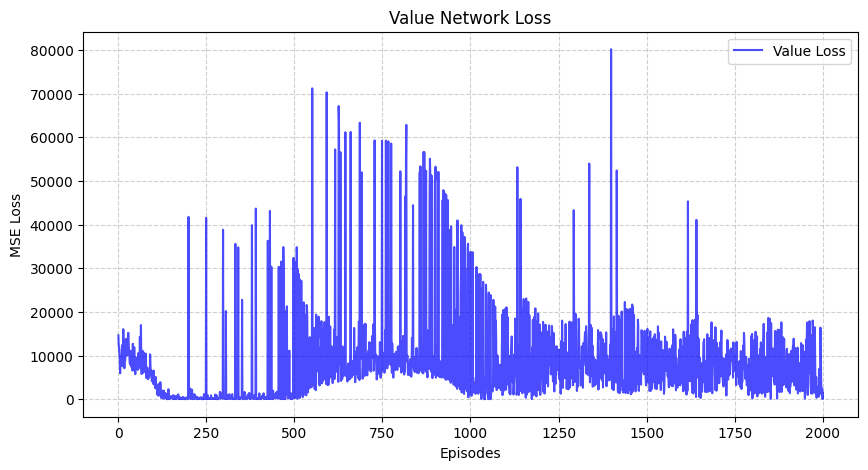

=== All 2000 Episodes ===
Idle           :    667 (5.46%)
Add Dough      :   3666 (30.03%)
Add Cheese     :   3579 (29.31%)
Add Pepperoni  :   2032 (16.64%)
Serve          :   2265 (18.55%)

=== Last 100 Episodes ===
Idle           :      0 (0.00%)
Add Dough      :    192 (34.78%)
Add Cheese     :    161 (29.17%)
Add Pepperoni  :     68 (12.32%)
Serve          :    131 (23.73%)

=== Last 100 Episodes Performance ===
Average Reward: 159.26
Successful Orders: 130
Timed-out Orders: 70
Success Rate: 65.00%
Timeout Rate: 35.00%


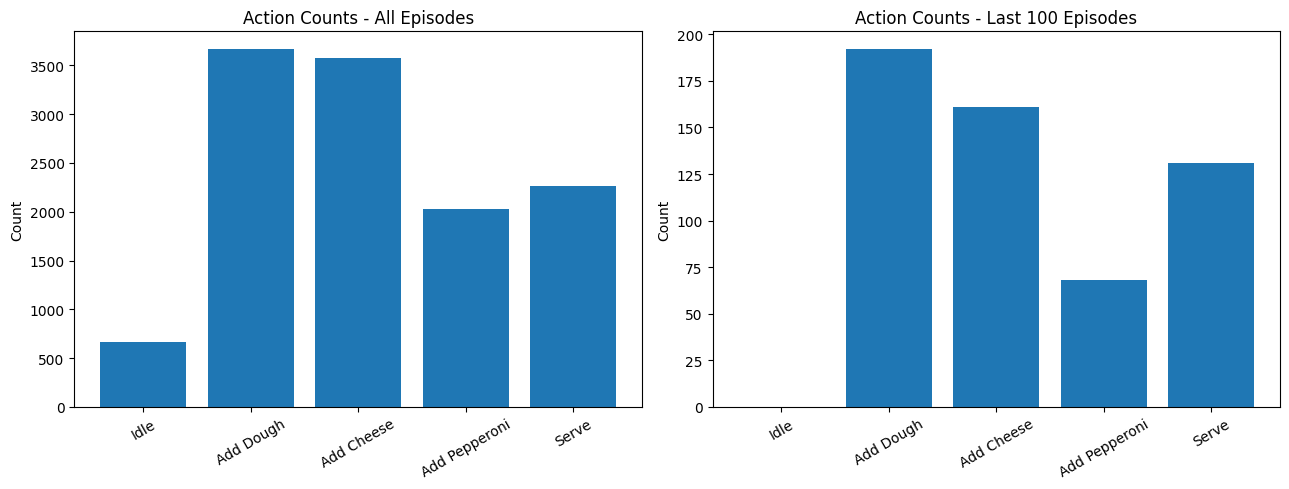

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=np.zeros(7, dtype=np.float32),
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(4, 9))
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (3)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

타임아웃 페널티를 -50으로 유지한 상태에서 정답 서빙 보상을 +20에서 +150으로 증가시킨 결과, 이전 실험과 달리 학습이 진행될수록 평균 보상이 뚜렷하게 상승함. 약 500 에피소드 이후 성능 개선이 나타나기 시작했으며, 1,000 에피소드 이후에는 평균 보상이 양수 구간에서 유지되는 경향을 보임. 최종 100 에피소드에서 평균 보상은 +159.26점, 주문 성공률은 65.00%, 타임아웃률은 35.00%로 나타남.

**원인 분석**:

1. 정답 서빙 보상이 +150으로 증가하면서 성공적인 행동 경로(Trajectory)를 통해 얻을 수 있는 보상이 커졌고, 에이전트가 피자 제작 행동을 강화할 수 있는 학습 신호가 형성된 것으로 판단됨.
2. 학습 후반 100 에피소드에서 Idle 행동 선택 비율은 0.00%로 감소했으며, Add Dough(34.78%), Add Cheese(29.17%), Add Pepperoni(12.32%), Serve(23.73%) 행동이 지속적으로 선택됨. 이는 이전 실험에서 관찰된 Idle 중심의 정책에서 벗어나 실제 피자 제작 및 서빙 행동을 수행하는 정책으로 변화했음을 보여줌.
3. Value Network Loss는 학습 후반에도 큰 변동을 보였으나, 평균 보상과 성공률은 개선됨. 따라서 가치 함수의 예측 오차가 완전히 안정화되지 않은 상태에서도 정책 성능이 향상될 수 있음을 확인함.

**결론 및 시사점**:

REINFORCE with Baseline의 3차 실험에서는 정답 서빙 보상을 +150으로 강화한 결과, 기존의 Idle 중심 정책에서 벗어나 실제 피자 제작 및 서빙 행동을 수행하는 정책을 학습할 수 있음을 확인함.

이는 앞선 실험에서 나타난 학습 부진이 알고리즘의 구조적 한계만으로 발생한 것이 아니라, 희소 보상 환경에서 성공적인 행동 경로(Trajectory)를 충분히 탐색하기 어려웠던 문제와 보상 구조의 영향을 함께 받았을 가능성을 보여줌.

특히 최종 100 에피소드에서 주문 성공률 65.00%, 평균 보상 +159.26점을 기록하며 유의미한 학습 성능 개선을 확인함. 다만 주문의 35.00%는 여전히 시간 초과로 처리되었고, Value Network Loss 역시 큰 변동을 보여 학습 성능과 안정성 측면에서 추가적인 개선 여지가 존재함.

**향후 발전 방향**:

우선 현재 학습에 성공한 REINFORCE with Baseline을 기반으로 대기 주문 수를 2개에서 4개로 확장하여, 환경 복잡도 증가가 학습 성능에 미치는 영향을 분석하고자 함.

####
## 실험 4. REINFORCE with Baseline - 메뉴 2개, 재료 3개, 최대 주문 대기 수 4개 (주문 타이머는 기존 4~8스텝으로 유지)

**실험 조건**:

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 4개

행동 종류: 5개

주문 타이머: 4~8스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -210.80 | Avg Reward (50): -217.18 | Success: 0 | Timeout: 4 | Value Loss: 25592.0352
Episode [100/2000] | Total Reward: -221.80 | Avg Reward (50): -208.82 | Success: 0 | Timeout: 4 | Value Loss: 9918.1816
Episode [150/2000] | Total Reward: -212.80 | Avg Reward (50): -208.02 | Success: 0 | Timeout: 4 | Value Loss: 1783.0231
Episode [200/2000] | Total Reward: -217.80 | Avg Reward (50): -193.57 | Success: 0 | Timeout: 4 | Value Loss: 1839.1663
Episode [250/2000] | Total Reward: -219.60 | Avg Reward (50): -192.36 | Success: 0 | Timeout: 4 | Value Loss: 1777.0717
Episode [300/2000] | Total Reward: -210.80 | Avg Reward (50): -189.07 | Success: 0 | Timeout: 4 | Value Loss: 1689.6627
Episode [350/2000] | Total Reward: -8.80 | Avg Reward (50): -182.25 | Success: 1 | Timeout: 3 | Value Loss: 32094.2500
Episode [400/2000] | Total Reward: -225.80 | Avg Reward (50): -163.69 | Success: 0 | Timeout: 4 | Value Loss: 1854.2766
Episode [450/2000] | Total Reward: -8.70 

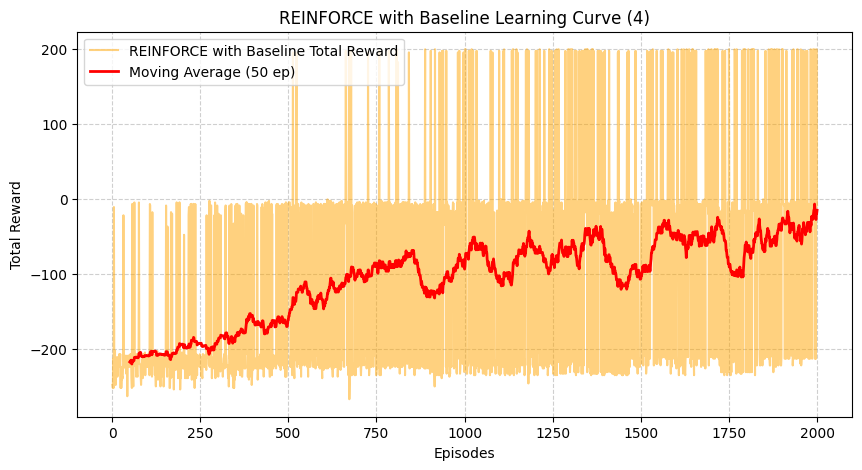

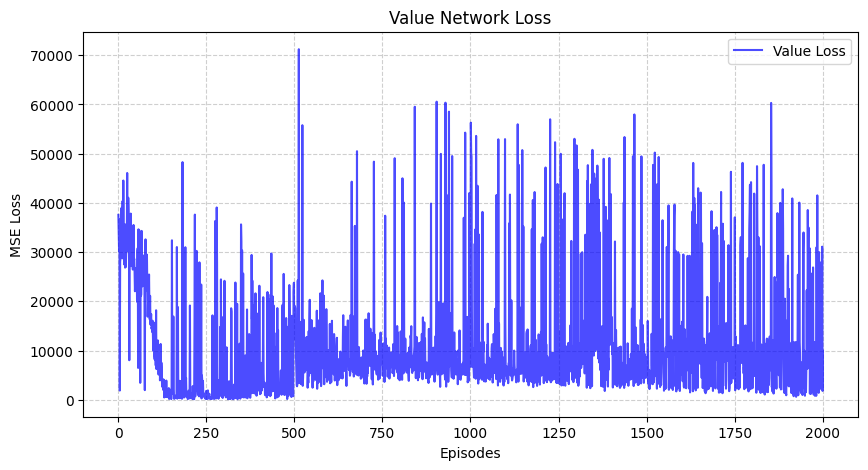

=== All 2000 Episodes ===
Idle           :    413 (2.85%)
Add Dough      :   6433 (44.43%)
Add Cheese     :   4663 (32.20%)
Add Pepperoni  :    562 (3.88%)
Serve          :   2409 (16.64%)

=== Last 100 Episodes ===
Idle           :      0 (0.00%)
Add Dough      :    378 (52.07%)
Add Cheese     :    256 (35.26%)
Add Pepperoni  :      0 (0.00%)
Serve          :     92 (12.67%)

=== Last 100 Episodes Performance ===
Average Reward: -29.34
Successful Orders: 89
Timed-out Orders: 311
Success Rate: 22.25%
Timeout Rate: 77.75%


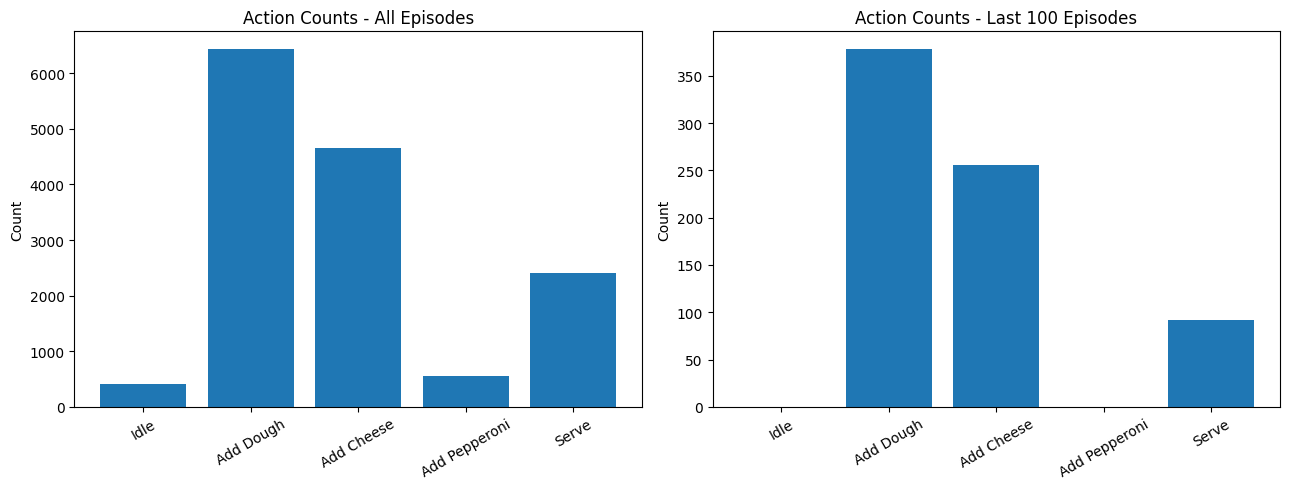

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # [d, c, p, m1, t1, m2, t2, m3, t3, m4, t4] = 11 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                [1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1],
                dtype=np.float32
            ),
            shape=(11,),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(4, 9))
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                f"Episode [{episode+1}/{num_episodes}] | "
                f"Total Reward: {total_reward:.2f} | "
                f"Avg Reward (50): {avg_reward:.2f} | "
                f"Success: {success_count} | "
                f"Timeout: {timeout_count} | "
                f"Value Loss: {value_loss.item():.4f}"
            )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (4)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

정답 서빙 보상 +150, 타임아웃 페널티 -50을 유지한 상태에서 최대 대기 주문 수를 2개에서 4개로 확장한 결과, 학습 초기 약 -200점대에 머물렀던 평균 보상이 학습 진행에 따라 점진적으로 상승함.

그러나 학습 후반에도 평균 보상의 변동이 크게 나타났으며, 최종 100 에피소드 기준 평균 보상은 -29.34점, 주문 성공률은 22.25%, 타임아웃률은 77.75%로 나타남. 이는 주문 2개 환경에서 기록한 성공률 65.00%보다 42.75%p 낮은 결과임.

**원인 분석**:

1. 최대 대기 주문 수가 4개로 증가했지만 주문 타이머는 기존 4~8스텝으로 유지됨. 모든 주문의 타이머가 동시에 감소하는 환경 구조상 제한 시간 내 4개 주문을 모두 처리하는 것은 불가능하며, 이러한 시간 제약이 성공률 감소에 영향을 미친 것으로 판단됨.

2. 학습 후반 100 에피소드에서 Idle 행동 비율은 0.00%로 나타나 피자 제작 행동을 수행하는 정책이 형성되었음을 확인함. 그러나 Add Dough(52.07%)와 Add Cheese(35.26%)에 행동이 집중되었으며, Add Pepperoni 행동은 0.00%로 나타남. 이는 환경 복잡도 증가에 따라 특정 행동에 편향된 정책이 학습되었을 가능성을 보여줌.

3. 학습 후반 일부 에피소드에서는 주문 2개를 성공적으로 처리하여 약 +199점의 보상을 획득하였으나, 주문을 전혀 처리하지 못하는 에피소드도 반복적으로 발생함. 또한 Value Network Loss가 큰 변동을 보여 학습 성능과 가치 함수 추정의 안정성이 충분히 확보되지 않았음을 확인함.

**결론 및 시사점**:

최대 대기 주문 수를 2개에서 4개로 확장한 결과, REINFORCE with Baseline은 학습이 진행됨에 따라 평균 보상을 개선하고 일부 주문을 성공적으로 처리하는 정책을 학습하였으나, 주문 성공률은 22.25%로 감소함.

이러한 결과는 주문 수 증가에 따른 환경 복잡도와 기존 타이머 조건의 시간적 제약이 학습 성능에 영향을 미칠 수 있음을 보여줌. 특히 모든 주문의 타이머가 동시에 감소하는 구조에서는 주문 처리 가능 횟수 자체가 제한되므로, 성공률 감소를 알고리즘의 성능 저하만으로 해석하기에는 한계가 있음.

향후에는 주문 타이머를 조정한 환경에서도 추가 실험을 수행하여 시간 제약의 영향을 분석하고자 함.

####
## 실험 5. REINFORCE with Baseline - 메뉴 2개, 재료 3개, 최대 주문 대기 수 4개 (주문 타이머는 16~24스텝으로 확장)
**실험 조건**:

메뉴 종류: 2개 (치즈, 페퍼로니)

재료 종류: 3개 (도우, 치즈, 페퍼로니)

최대 주문 대기 수: 4개

행동 종류: 5개

주문 타이머: 16~24스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -275.40 | Avg Reward (50): -203.90 | Success: 0 | Timeout: 4 | Value Loss: 35671.4648
Episode [100/2000] | Total Reward: 169.70 | Avg Reward (50): -154.69 | Success: 2 | Timeout: 2 | Value Loss: 28429.4258
Episode [150/2000] | Total Reward: -75.40 | Avg Reward (50): -134.83 | Success: 1 | Timeout: 3 | Value Loss: 8090.4937
Episode [200/2000] | Total Reward: 119.90 | Avg Reward (50): -141.71 | Success: 2 | Timeout: 2 | Value Loss: 30380.9785
Episode [250/2000] | Total Reward: -50.00 | Avg Reward (50): -113.80 | Success: 1 | Timeout: 3 | Value Loss: 6049.1865
Episode [300/2000] | Total Reward: 385.80 | Avg Reward (50): -70.88 | Success: 3 | Timeout: 1 | Value Loss: 89130.0703
Episode [350/2000] | Total Reward: -48.40 | Avg Reward (50): -65.02 | Success: 1 | Timeout: 3 | Value Loss: 4907.9575
Episode [400/2000] | Total Reward: 377.70 | Avg Reward (50): 32.93 | Success: 3 | Timeout: 1 | Value Loss: 83998.7891
Episode [450/2000] | Total Reward: 134.80 | Avg

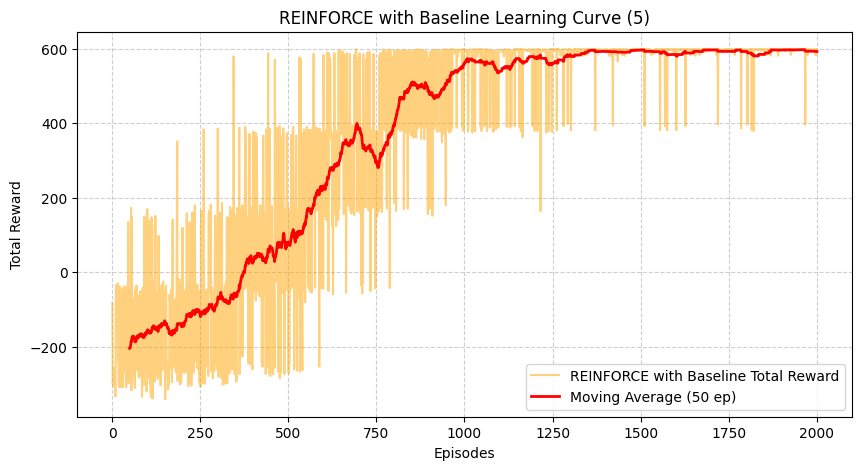

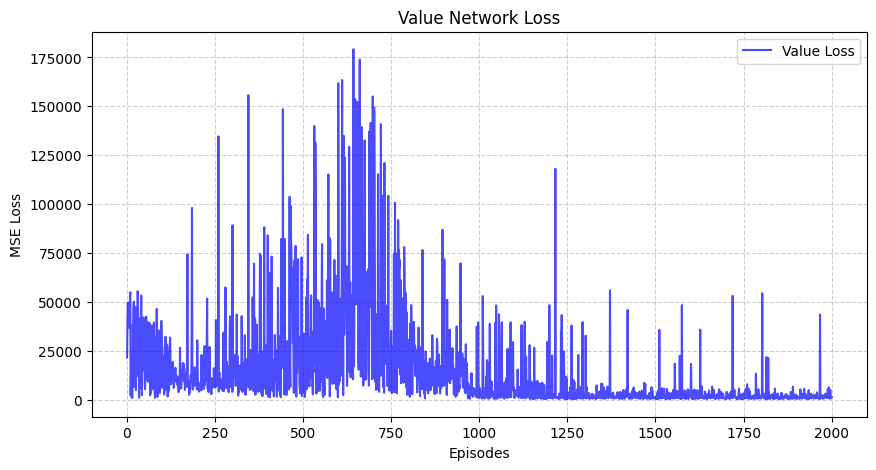

=== All 2000 Episodes ===
Idle           :   1961 (5.48%)
Add Dough      :  10761 (30.09%)
Add Cheese     :  10456 (29.24%)
Add Pepperoni  :   5199 (14.54%)
Serve          :   7382 (20.64%)

=== Last 100 Episodes ===
Idle           :      2 (0.14%)
Add Dough      :    422 (28.92%)
Add Cheese     :    420 (28.79%)
Add Pepperoni  :    212 (14.53%)
Serve          :    403 (27.62%)

=== Last 100 Episodes Performance ===
Average Reward: 595.06
Successful Orders: 399
Timed-out Orders: 1
Success Rate: 99.75%
Timeout Rate: 0.25%


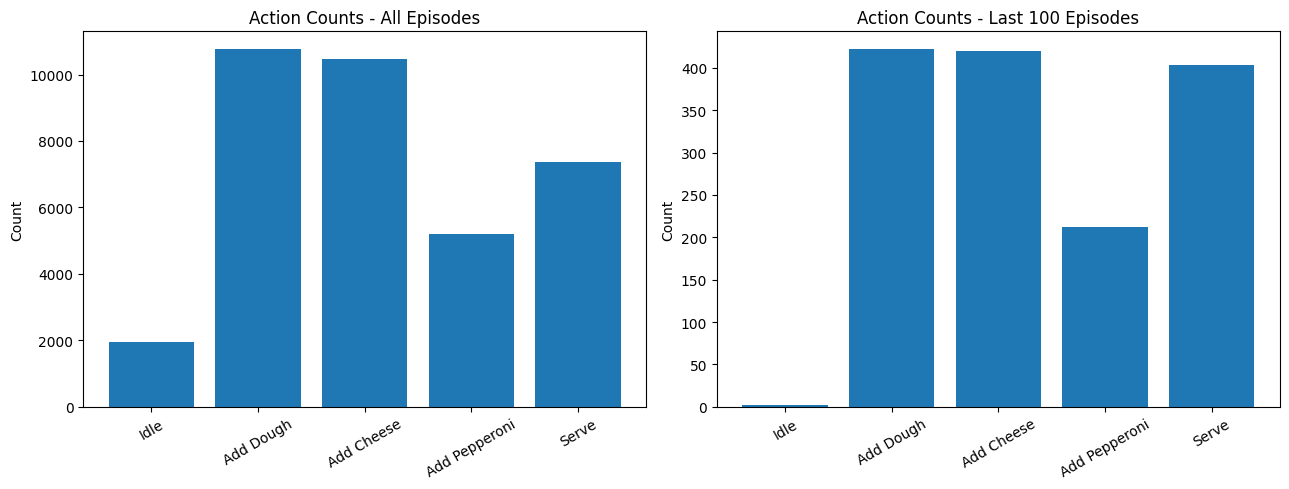

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # [d, c, p, m1, t1, m2, t2, m3, t3, m4, t4] = 11 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                [1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1],
                dtype=np.float32
            ),
            shape=(11,),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough, 2: Add Cheese,
        # 3: Add Pepperoni, 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0],  # Cheese Pizza
            2: [1.0, 1.0, 1.0]   # Pepperoni Pizza
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2]))
            timer = int(self.np_random.integers(16, 25)) # ⭐ 주문 타이머 4~8 → 16~24스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 24.0) # ⭐ 타이머 최댓값 24 기준 정규화 (기존 8 → 24)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Serve
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32)
                else:
                    reward -= 15.0
                    self.counter = np.zeros(3, dtype=np.float32)
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(5, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 4 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
    )

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (5)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
    )

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
torch.save(
    policy_net.state_dict(),
    "reinforce_baseline_5.pth"
)

**현상**:

최대 대기 주문 수를 4개로 유지한 상태에서 주문 타이머를 기존 4 ~ 8스텝에서 16 ~ 24스텝으로 확장한 결과, 학습이 진행됨에 따라 평균 보상이 크게 상승함. 약 400 에피소드 이후 이동 평균 보상이 양수 구간에 진입하였으며, 약 1,300 에피소드 이후에는 600점에 가까운 수준을 유지하는 경향을 보임.

최종 100 에피소드 기준 평균 보상은 +595.06점, 주문 성공률은 99.75%, 타임아웃률은 0.25%로 나타남. 이는 동일한 주문 수에서 타이머를 4~8스텝으로 유지했던 실험 4의 성공률 22.25%보다 77.50%p 높은 결과임.

**원인 분석**:

1. 주문 타이머를 16~24스텝으로 확장하면서 에이전트가 4개 주문을 처리할 수 있는 시간적 여유가 증가함. 이에 따라 기존 환경에서 발생했던 구조적인 시간 제약이 완화되었으며, 성공적인 주문 처리 경험을 더 많이 확보할 수 있었던 것으로 판단됨.

2. 학습 후반 100 에피소드에서 Idle 행동 비율은 0.14%로 매우 낮게 나타났으며, Add Dough(28.92%), Add Cheese(28.79%), Add Pepperoni(14.53%), Serve(27.62%) 행동이 비교적 균형 있게 선택됨. 특히 실험 4에서 0.00%였던 Add Pepperoni 행동이 다시 나타나면서 두 종류의 피자 제작에 필요한 행동을 모두 수행하는 정책이 형성되었음을 보여줌.

3. Value Network Loss는 학습 초기와 중반에 큰 변동을 보였으나, 학습 후반에는 전반적으로 감소하는 경향을 나타냄. 이는 평균 보상과 주문 성공률이 개선되는 과정에서 가치 함수의 예측 오차 역시 감소했을 가능성을 보여줌. 다만 일부 급격한 변동이 남아 있어 완전한 안정화로 단정하기는 어려움.

**결론 및 시사점**:

REINFORCE with Baseline의 실험 5에서는 주문 타이머를 확장한 결과, 최대 대기 주문 수가 4개인 환경에서도 주문 성공률 99.75%와 평균 보상 +595.06점을 기록하며 높은 학습 성능을 달성함.

이는 실험 4에서 나타난 성능 저하가 주문 수 증가에 따른 학습 난이도뿐 아니라, 짧은 주문 타이머로 인한 시간적 제약과 밀접하게 관련되어 있었을 가능성을 보여줌.

따라서 강화학습 알고리즘의 성능을 비교할 때는 주문 수와 같은 환경 복잡도뿐 아니라, 실제로 주문을 처리할 수 있는 시간적 조건도 함께 고려해야 함.

**향후 발전 방향**:

다음 실험에서는 메뉴 종류를 2개에서 4개로, 재료 종류를 3개에서 5개로, 행동 종류를 5개에서 7개로 확장하여 환경 복잡도 증가에 따른 학습 성능 변화를 분석하고자 함.

특히 앞선 실험에서 확인한 시간적 제약의 영향을 고려하여 주문 타이머를 24~36스텝으로 조정하고, 최대 복잡도 환경에서 REINFORCE with Baseline의 학습 가능성, 주문 성공률 및 학습 안정성을 평가할 계획임.

## 실험 6-1. REINFORCE with Baseline - 메뉴 4개, 재료 5개, 최대 주문 대기 수 4개 (주문 타이머는 24~36스텝으로 확장, 시드 42)

**실험 조건**:

메뉴 종류: 4개 (치즈, 페퍼로니, 버섯, 스페셜)

재료 종류: 5개 (도우, 치즈, 페퍼로니, 버섯, 올리브)

최대 주문 대기 수: 4개

행동 종류: 7개

주문 타이머: 24~36스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -283.60 | Avg Reward (50): -226.82 | Success: 0 | Timeout: 4 | Value Loss: 35784.3281
Episode [100/2000] | Total Reward: -271.50 | Avg Reward (50): -256.18 | Success: 0 | Timeout: 4 | Value Loss: 12238.9170
Episode [150/2000] | Total Reward: -247.50 | Avg Reward (50): -255.49 | Success: 0 | Timeout: 4 | Value Loss: 7212.9082
Episode [200/2000] | Total Reward: -261.50 | Avg Reward (50): -245.48 | Success: 0 | Timeout: 4 | Value Loss: 1544.9971
Episode [250/2000] | Total Reward: -239.90 | Avg Reward (50): -237.19 | Success: 0 | Timeout: 4 | Value Loss: 372.8610
Episode [300/2000] | Total Reward: -263.40 | Avg Reward (50): -224.97 | Success: 0 | Timeout: 4 | Value Loss: 2074.9875
Episode [350/2000] | Total Reward: -275.60 | Avg Reward (50): -228.20 | Success: 0 | Timeout: 4 | Value Loss: 3557.1707
Episode [400/2000] | Total Reward: -238.50 | Avg Reward (50): -226.35 | Success: 0 | Timeout: 4 | Value Loss: 1303.2231
Episode [450/2000] | Total Reward: -239.

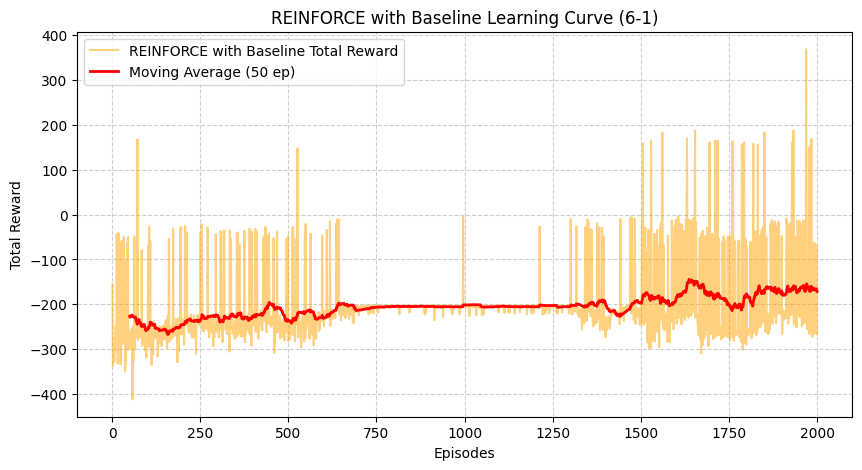

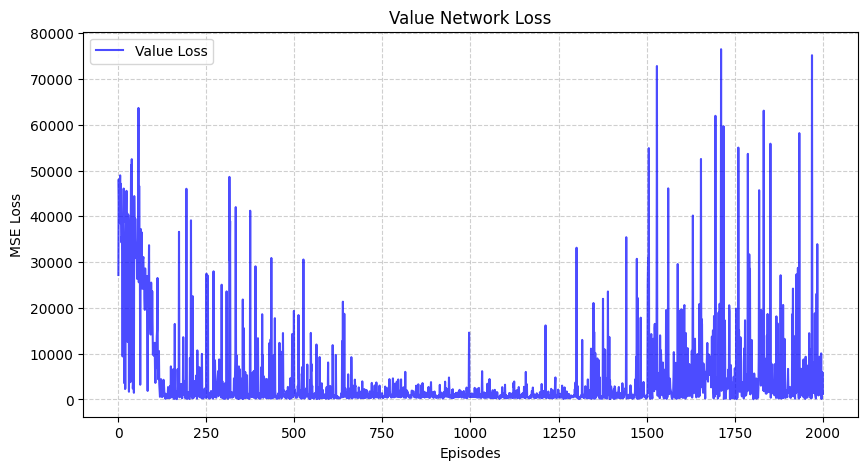

=== All 2000 Episodes ===
Idle           :  42043 (62.41%)
Add Dough      :  12193 (18.10%)
Add Cheese     :   4835 (7.18%)
Add Pepperoni  :   2556 (3.79%)
Add Mushroom   :   1977 (2.93%)
Add Olive      :   2145 (3.18%)
Serve          :   1614 (2.40%)

=== Last 100 Episodes ===
Idle           :   1838 (54.33%)
Add Dough      :   1099 (32.49%)
Add Cheese     :    306 (9.05%)
Add Pepperoni  :     45 (1.33%)
Add Mushroom   :      2 (0.06%)
Add Olive      :      2 (0.06%)
Serve          :     91 (2.69%)

=== Last 100 Episodes Performance ===
Average Reward: -170.93
Successful Orders: 32
Timed-out Orders: 368
Success Rate: 8.00%
Timeout Rate: 92.00%


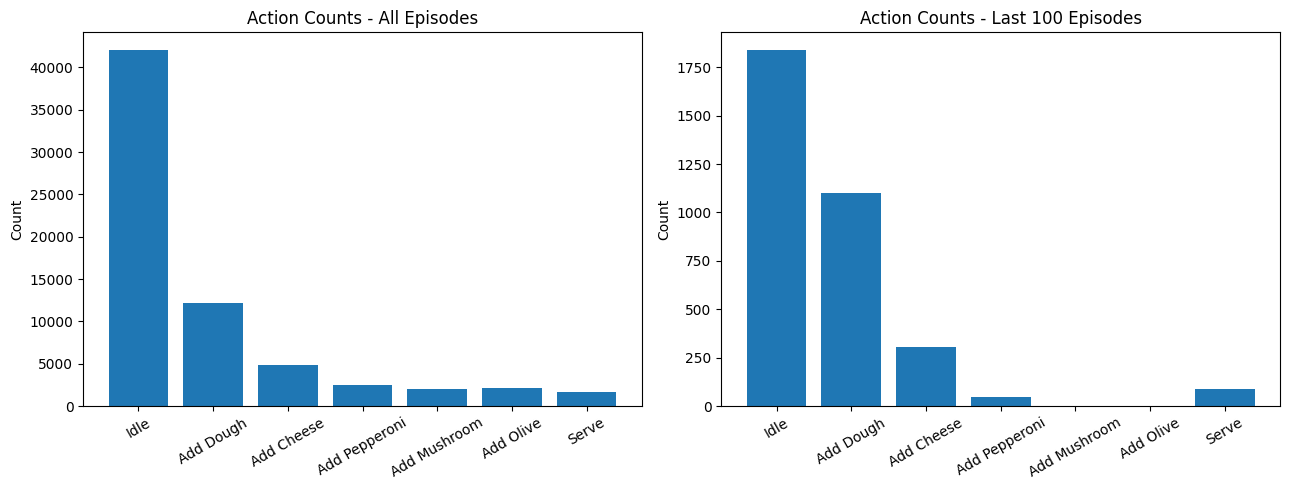

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # ⭐ [d, c, p, m, o, m1, t1, m2, t2, m3, t3, m4, t4]
        # 재료 5개 + 주문 정보 8개 = 13차원
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                            [1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1],
                            dtype=np.float32
            ),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(7)
        self.menus = {
            1: [1., 1., 0., 0., 0.],  # 치즈
            2: [1., 1., 1., 0., 0.],  # 페퍼로니
            3: [1., 1., 0., 1., 0.],  # 버섯
            4: [1., 1., 1., 1., 1.]   # 스페셜
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2, 3, 4]))
            timer = int(self.np_random.integers(24, 37)) # ⭐ 주문 타이머 16~24 → 24~36스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 36.0) # ⭐ 타이머 최댓값 36 기준 정규화 (기존 24 → 36)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Add Mushroom ⭐ 추가
            if self.counter[3] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[3] = 1.0

        elif action == 5:  # Add Olive ⭐ 추가
            if self.counter[4] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[4] = 1.0

        elif action == 6:  # Serve ⭐ 기존 4 → 6
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
                else:
                    reward -= 15.0
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(7, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (6-1)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Add Mushroom',
    'Add Olive',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

메뉴 종류를 2개에서 4개로, 재료 종류를 3개에서 5개로, 행동 종류를 5개에서 7개로 확장하고 주문 타이머를 24~36스텝으로 조정한 결과, 이전 실험 5와 달리 학습 성능이 크게 저하됨.

학습 초기에는 평균 보상이 약 -250점 수준에서 나타났으며, 약 700~1,300 에피소드 구간에서는 -200점 부근에 머무르는 경향을 보임. 약 1,500 에피소드 이후 일부 주문 성공 사례가 증가하면서 평균 보상이 소폭 개선되었으나, 학습 종료 시점까지 음수 구간을 벗어나지 못함.

최종 100 에피소드에서 평균 보상은 -170.93점, 주문 성공률은 8.00%, 타임아웃률은 92.00%로 나타남. 이는 실험 5의 주문 성공률 99.75%와 비교하여 91.75%p 감소한 결과임.

**원인 분석**:

메뉴와 재료, 행동 종류가 증가하면서 에이전트가 탐색해야 하는 상태 및 행동 공간이 확장됨. 특히 메뉴별로 요구되는 재료 조합이 다양해지면서 성공적인 피자 제작 및 서빙을 위한 행동 경로가 복잡해졌고, 제한된 학습 에피소드 내에서 효과적인 정책을 학습하기 어려웠을 가능성이 있음.

학습 후반 100 에피소드에서 Idle 행동 선택 비율은 54.33%로 가장 높게 나타났으며, Add Dough(32.49%), Add Cheese(9.05%), Add Pepperoni(1.33%), Add Mushroom(0.06%), Add Olive(0.06%), Serve(2.69%) 순으로 나타남. 특히 새롭게 추가된 버섯과 올리브 행동의 선택 비율이 매우 낮아, 확장된 메뉴를 처리하는 데 필요한 행동을 충분히 학습하지 못한 것으로 판단됨.

Value Network Loss는 학습 초기에 감소하는 경향을 보였으나, 학습 후반에는 다시 큰 변동이 나타남. 이는 주문 성공 경험이 제한적으로 발생하는 상황에서 가치 함수의 예측 오차가 안정적으로 감소하지 못했을 가능성을 보여줌. 다만 Value Loss의 변동만으로 학습 성능 저하의 직접적인 원인을 단정하기는 어려움.

실험 5에서는 타이머 확장을 통해 높은 주문 성공률을 달성했으나, 실험 6에서는 타이머를 추가로 확장했음에도 성공률이 크게 감소함. 이는 시간적 제약의 완화만으로는 증가한 메뉴 및 행동의 복잡도에 충분히 대응하기 어려웠음을 시사함. 다만 실험 5와 6에서는 환경 복잡도와 타이머 조건이 함께 변경되었으므로, 성능 저하를 특정 요소 하나의 영향으로 단정할 수는 없음.

**결론 및 시사점**:

실험 6-1에서는 최대 복잡도 환경으로 확장한 결과, 주문 성공률 8.00%와 평균 보상 -170.93점을 기록하며 이전 실험에 비해 학습 성능이 크게 저하됨.

학습 후반에 일부 주문 성공 사례와 평균 보상의 개선이 나타났으나, Idle 행동의 높은 선택 비율과 새로운 재료 행동의 낮은 활용도를 고려할 때 이번 실행에서는 안정적인 주문 처리 정책을 충분히 형성하지 못한 것으로 판단됨.

이는 주문 타이머를 확장하더라도 메뉴와 재료, 행동 종류가 증가한 환경에서는 학습에 어려움이 발생할 수 있음을 보여줌. 다만 현재 결과는 단일 학습 실행에 기반하므로, 이러한 성능 저하가 랜덤 초기화 및 탐색 과정의 영향인지, 환경 복잡도 증가에 따른 일관된 현상인지는 추가 확인이 필요함.

**향후 발전 방향**:

실험 6-1에서 나타난 성능 저하가 랜덤 시드에 따라 달라지는지 확인하기 위해, 동일한 환경 및 학습 조건에서 랜덤 시드만 변경한 실험 6-2를 추가로 진행하고자 함.

반복 실행 결과를 바탕으로 평균 보상, 주문 성공률, 행동 선택 비율 및 학습 안정성을 비교하여 성능 변화의 일관성을 검토할 계획임.

## 실험 6-2. REINFORCE with Baseline - 메뉴 4개, 재료 5개, 최대 주문 대기 수 4개 (시드 123)

**실험 조건**:

메뉴 종류: 4개 (치즈, 페퍼로니, 버섯, 스페셜)

재료 종류: 5개 (도우, 치즈, 페퍼로니, 버섯, 올리브)

최대 주문 대기 수: 4개

행동 종류: 7개

주문 타이머: 24~36스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -328.40 | Avg Reward (50): -280.03 | Success: 0 | Timeout: 4 | Value Loss: 43959.6758
Episode [100/2000] | Total Reward: -255.10 | Avg Reward (50): -253.39 | Success: 0 | Timeout: 4 | Value Loss: 13176.6865
Episode [150/2000] | Total Reward: -296.60 | Avg Reward (50): -242.91 | Success: 0 | Timeout: 4 | Value Loss: 3195.0581
Episode [200/2000] | Total Reward: -73.30 | Avg Reward (50): -238.01 | Success: 1 | Timeout: 3 | Value Loss: 18633.1016
Episode [250/2000] | Total Reward: -287.60 | Avg Reward (50): -253.66 | Success: 0 | Timeout: 4 | Value Loss: 2088.0125
Episode [300/2000] | Total Reward: -259.80 | Avg Reward (50): -237.83 | Success: 0 | Timeout: 4 | Value Loss: 150.3769
Episode [350/2000] | Total Reward: -72.40 | Avg Reward (50): -250.44 | Success: 1 | Timeout: 3 | Value Loss: 15864.2021
Episode [400/2000] | Total Reward: -276.40 | Avg Reward (50): -235.87 | Success: 0 | Timeout: 4 | Value Loss: 304.6609
Episode [450/2000] | Total Reward: -86.50

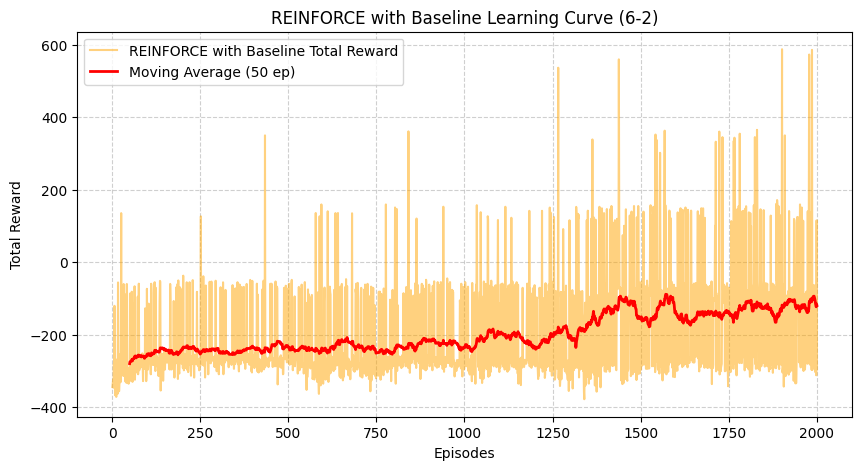

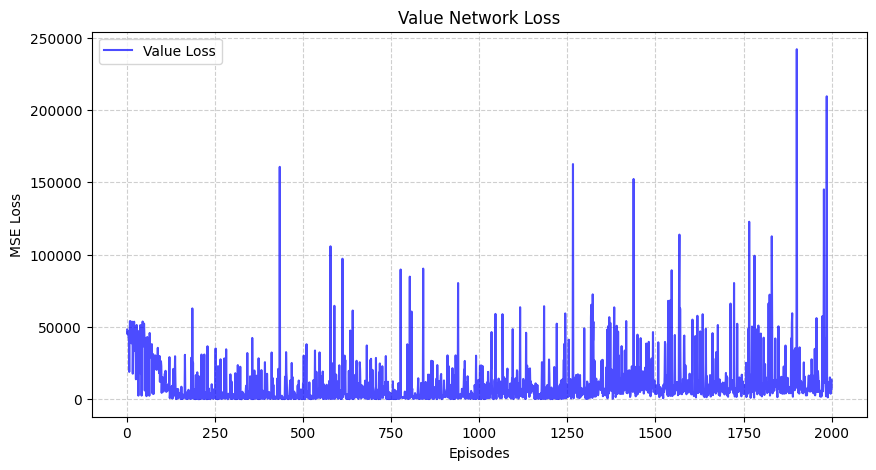

=== All 2000 Episodes ===
Idle           :   1689 (2.53%)
Add Dough      :  23513 (35.17%)
Add Cheese     :  20611 (30.83%)
Add Pepperoni  :   1854 (2.77%)
Add Mushroom   :  12920 (19.32%)
Add Olive      :   1465 (2.19%)
Serve          :   4811 (7.20%)

=== Last 100 Episodes ===
Idle           :     17 (0.52%)
Add Dough      :    757 (22.97%)
Add Cheese     :    775 (23.52%)
Add Pepperoni  :     12 (0.36%)
Add Mushroom   :   1402 (42.55%)
Add Olive      :      1 (0.03%)
Serve          :    331 (10.05%)

=== Last 100 Episodes Performance ===
Average Reward: -121.84
Successful Orders: 80
Timed-out Orders: 320
Success Rate: 20.00%
Timeout Rate: 80.00%


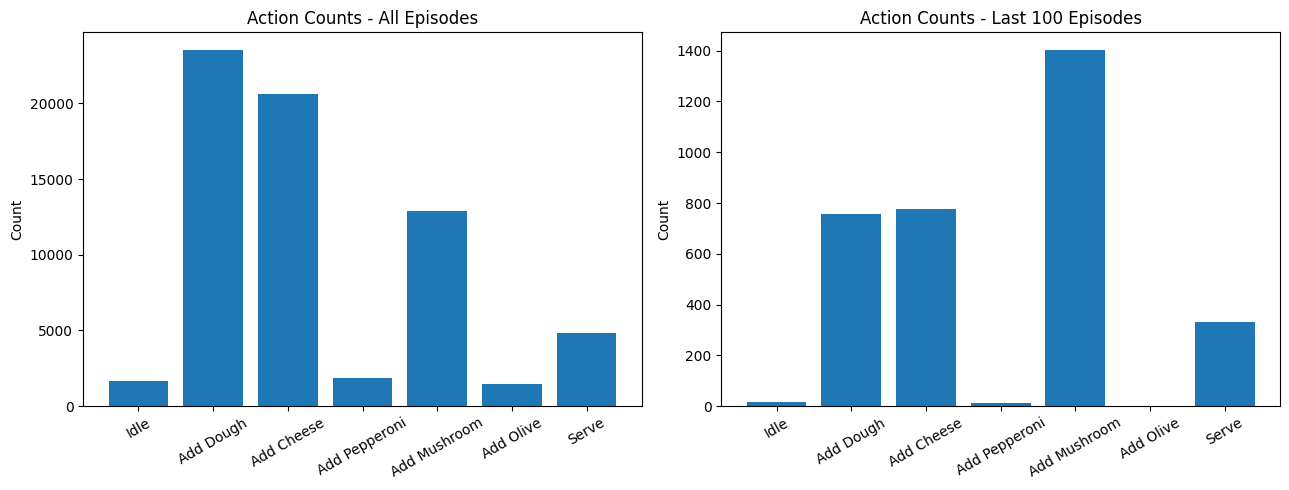

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # ⭐ [d, c, p, m, o, m1, t1, m2, t2, m3, t3, m4, t4]
        # 재료 5개 + 주문 정보 8개 = 13차원
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                            [1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1],
                            dtype=np.float32
            ),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(7)
        self.menus = {
            1: [1., 1., 0., 0., 0.],  # 치즈
            2: [1., 1., 1., 0., 0.],  # 페퍼로니
            3: [1., 1., 0., 1., 0.],  # 버섯
            4: [1., 1., 1., 1., 1.]   # 스페셜
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2, 3, 4]))
            timer = int(self.np_random.integers(24, 37)) # ⭐ 주문 타이머 16~24 → 24~36스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 36.0) # ⭐ 타이머 최댓값 36 기준 정규화 (기존 24 → 36)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Add Mushroom ⭐ 추가
            if self.counter[3] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[3] = 1.0

        elif action == 5:  # Add Olive ⭐ 추가
            if self.counter[4] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[4] = 1.0

        elif action == 6:  # Serve ⭐ 기존 4 → 6
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
                else:
                    reward -= 15.0
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(7, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(123)

env = PizzaShopEnv()
env.reset(seed=123)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (6-2)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Add Mushroom',
    'Add Olive',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

실험 6-2에서는 학습 초기 평균 보상이 약 -280점 수준에서 시작하였으며, 약 1,300에피소드 이후 평균 보상이 점진적으로 개선되는 경향을 보임. 그러나 학습 종료 시점까지 평균 보상은 음수 구간에 머물렀으며, 에피소드별 보상 변동도 크게 나타남.

최종 100에피소드에서 평균 보상은 -121.84점, 주문 성공률은 20.00%, 타임아웃률은 80.00%로 나타남. 이는 실험 6-1의 평균 보상 -170.93점, 주문 성공률 8.00%와 비교하여 개선된 결과임.

**원인 분석**:

실험 6-1에서는 마지막 100에피소드의 Idle 행동 비율이 54.33%였으나, 실험 6-2에서는 0.52%로 크게 감소함. 반면 Add Mushroom 행동 비율은 42.55%로 가장 높게 나타났으며, Add Pepperoni(0.36%)와 Add Olive(0.03%)의 선택 비율은 매우 낮았음.

이는 실험 6-1과 달리 실험 6-2에서는 대기 행동에 집중하는 현상이 줄어들었지만, 특정 재료 행동에 편중된 정책이 형성되었음을 보여줌. 이러한 행동 편중은 다양한 재료 조합을 요구하는 메뉴를 처리하는 데 제약으로 작용했을 가능성이 있음.

또한 Value Network Loss는 학습 후반에도 큰 변동을 반복하여, 가치 함수의 예측 오차가 안정적으로 감소하지 못한 것으로 나타남. 다만 이러한 손실 변동만으로 성능 저하의 원인을 단정하기는 어려움.

**결론 및 시사점**:

동일한 최대 복잡도 환경에서 랜덤 시드만 변경한 결과, 실험 6-2의 주문 성공률은 20.00%로 실험 6-1의 8.00%보다 높게 나타남. 그러나 두 실험 모두 높은 타임아웃률과 특정 행동에 대한 편중을 보였으며, 안정적인 주문 처리 정책을 형성하지 못함.

이를 통해 REINFORCE with Baseline의 학습 결과가 랜덤 시드에 따라 달라질 수 있음을 관찰하였으며, 최대 복잡도 환경에서의 학습 성능을 평가할 때 단일 실행 결과만으로 결론을 내리기 어렵다는 점을 확인함.

## 실험 7-1. REINFORCE with Baseline - 메뉴 4개, 재료 5개, 최대 주문 대기 수 4개 (시드 42, 주문 타이머 36~48스텝으로 확장)

**실험 조건**:

메뉴 종류: 4개 (치즈, 페퍼로니, 버섯, 스페셜)

재료 종류: 5개 (도우, 치즈, 페퍼로니, 버섯, 올리브)

최대 주문 대기 수: 4개

행동 종류: 7개

주문 타이머: 36~48스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -90.80 | Avg Reward (50): -248.24 | Success: 1 | Timeout: 3 | Value Loss: 10111.1982
Episode [100/2000] | Total Reward: -331.70 | Avg Reward (50): -261.41 | Success: 0 | Timeout: 4 | Value Loss: 20204.1348
Episode [150/2000] | Total Reward: -310.70 | Avg Reward (50): -281.62 | Success: 0 | Timeout: 4 | Value Loss: 1531.9554
Episode [200/2000] | Total Reward: -281.70 | Avg Reward (50): -282.35 | Success: 0 | Timeout: 4 | Value Loss: 1057.8395
Episode [250/2000] | Total Reward: -298.10 | Avg Reward (50): -266.07 | Success: 0 | Timeout: 4 | Value Loss: 296.0972
Episode [300/2000] | Total Reward: -293.60 | Avg Reward (50): -276.81 | Success: 0 | Timeout: 4 | Value Loss: 1035.5975
Episode [350/2000] | Total Reward: -80.50 | Avg Reward (50): -271.26 | Success: 1 | Timeout: 3 | Value Loss: 20265.3027
Episode [400/2000] | Total Reward: -286.70 | Avg Reward (50): -258.36 | Success: 0 | Timeout: 4 | Value Loss: 376.7127
Episode [450/2000] | Total Reward: -291.50

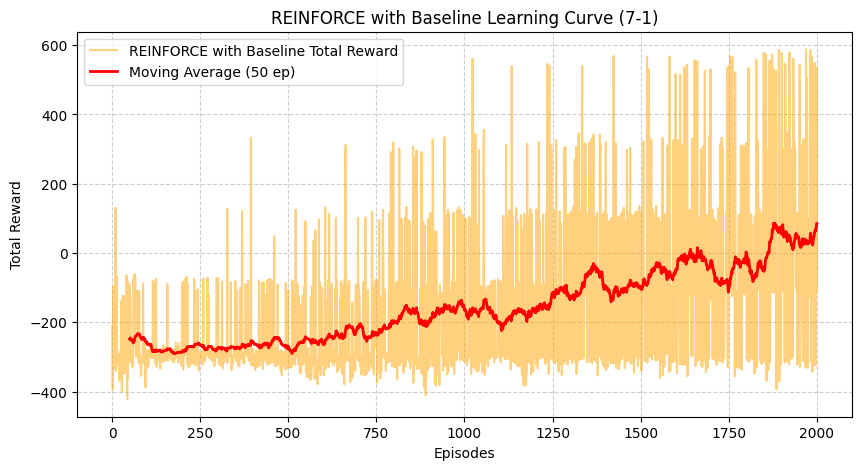

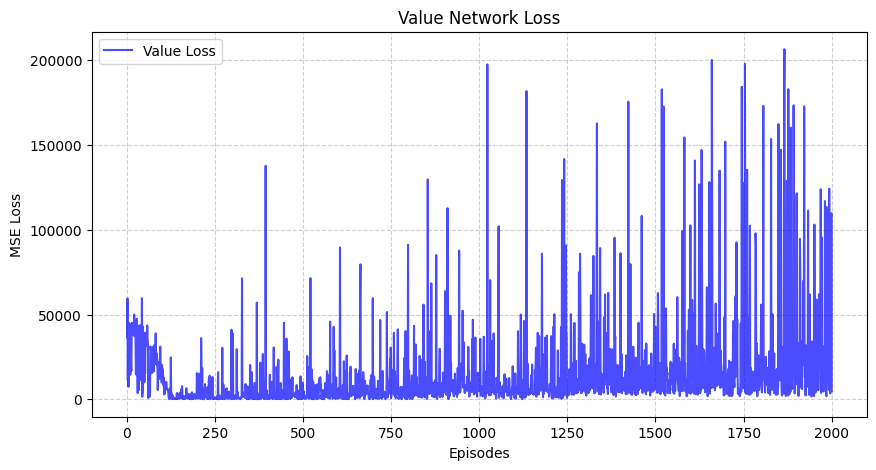

=== All 2000 Episodes ===
Idle           :   4265 (4.76%)
Add Dough      :  31123 (34.70%)
Add Cheese     :  28655 (31.95%)
Add Pepperoni  :   6481 (7.23%)
Add Mushroom   :   8532 (9.51%)
Add Olive      :   3692 (4.12%)
Serve          :   6943 (7.74%)

=== Last 100 Episodes ===
Idle           :      3 (0.07%)
Add Dough      :   1070 (24.85%)
Add Cheese     :   1884 (43.75%)
Add Pepperoni  :    185 (4.30%)
Add Mushroom   :    727 (16.88%)
Add Olive      :     10 (0.23%)
Serve          :    427 (9.92%)

=== Last 100 Episodes Performance ===
Average Reward: 55.14
Successful Orders: 174
Timed-out Orders: 226
Success Rate: 43.50%
Timeout Rate: 56.50%


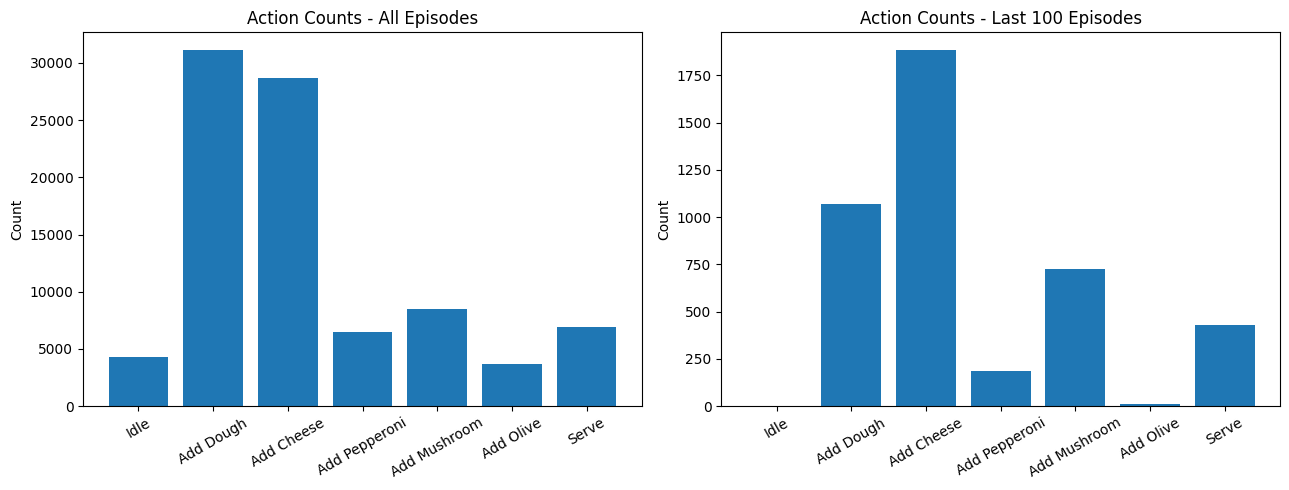

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # ⭐ [d, c, p, m, o, m1, t1, m2, t2, m3, t3, m4, t4]
        # 재료 5개 + 주문 정보 8개 = 13차원
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                            [1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1],
                            dtype=np.float32
            ),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(7)
        self.menus = {
            1: [1., 1., 0., 0., 0.],  # 치즈
            2: [1., 1., 1., 0., 0.],  # 페퍼로니
            3: [1., 1., 0., 1., 0.],  # 버섯
            4: [1., 1., 1., 1., 1.]   # 스페셜
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2, 3, 4]))
            timer = int(self.np_random.integers(36, 49)) # ⭐ 주문 타이머 24~36 → 36~48스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 48.0) # ⭐ 타이머 최댓값 48 기준 정규화 (기존 36 → 48)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Add Mushroom ⭐ 추가
            if self.counter[3] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[3] = 1.0

        elif action == 5:  # Add Olive ⭐ 추가
            if self.counter[4] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[4] = 1.0

        elif action == 6:  # Serve ⭐ 기존 4 → 6
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
                else:
                    reward -= 15.0
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(7, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(42)

env = PizzaShopEnv()
env.reset(seed=42)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (7-1)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Add Mushroom',
    'Add Olive',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**현상**:

실험 6-1과 동일한 랜덤 시드(42) 및 환경 조건에서 주문 타이머를 24 ~ 36스텝에서 36 ~ 48스텝으로 증가시킨 결과, 최근 100에피소드 기준 평균 보상이 -170.93에서 +55.14로 증가하고 주문 성공률도 8.00%에서 43.50%로 개선되는 현상이 관찰됨.

학습 초반에는 이동 평균 보상이 약 -250점 부근에 머물렀으나, 학습이 진행될수록 점차 상승하여 후반부에는 양수 구간에 진입함. 또한 Idle 행동 비율이 54.33%에서 0.07%로 크게 감소하고 재료 추가 및 서빙 행동의 비중이 증가함.

다만 주문 타임아웃 비율은 여전히 56.50%로 높게 나타났으며, 가치 함수 손실에서도 큰 변동이 지속됨.

**원인 분석**:

실험 6-1과 비교하여 주문 타이머만 증가시켰으므로, 주문 처리에 사용할 수 있는 시간이 늘어난 것이 학습 성능 개선에 영향을 미친 것으로 판단됨.

기존에는 제한된 시간 내에 여러 재료를 순서대로 추가하고 서빙하는 행동을 학습하기 어려웠으나, 타이머가 증가하면서 성공적인 주문 처리 경험을 얻을 기회가 확대되었을 가능성이 있음.

실제로 Idle 행동이 크게 감소하고 재료 추가 및 서빙 행동이 증가한 점은 에이전트가 이전보다 적극적으로 피자 제작을 시도하는 정책을 학습했음을 보여줌.

그러나 Add Cheese 행동이 43.75%를 차지하는 반면 Add Olive 행동은 0.23%에 그쳐, 일부 재료에 대한 행동 편중이 여전히 나타남. 이는 복잡한 메뉴별 재료 조합을 충분히 학습하지 못한 원인 중 하나일 가능성이 있음.

**결론 및 시사점**:

주문 타이머를 36~48스텝으로 확장한 결과, 실험 6-1 대비 평균 보상은 -170.93에서 +55.14로 증가하고 주문 성공률은 8.00%에서 43.50%로 개선됨. 이를 통해 복잡한 환경에서 충분한 주문 처리 시간을 확보하는 것이 학습 성능 향상에 긍정적인 영향을 미칠 수 있음을 확인함.

특히 Idle 행동 비율이 크게 감소하고 재료 추가 및 서빙 행동이 증가한 점에서, 타이머 확장이 에이전트의 적극적인 주문 처리 행동을 유도하는 데 기여했을 가능성이 있음.

다만 주문 성공률은 43.50%에 머물렀으며, 일부 재료에 대한 행동 편중과 가치 함수 손실의 큰 변동이 지속됨. 따라서 타이머 확장으로 학습 성능은 개선되었으나, 안정적인 주문 처리 정책을 충분히 학습하는 데에는 여전히 한계가 있음을 확인함.

## 실험 7-2. REINFORCE with Baseline - 메뉴 4개, 재료 5개, 최대 주문 대기 수 4개 (시드 123, 주문 타이머 36~48스텝으로 확장)

**실험 조건**:

메뉴 종류: 4개 (치즈, 페퍼로니, 버섯, 스페셜)

재료 종류: 5개 (도우, 치즈, 페퍼로니, 버섯, 올리브)

최대 주문 대기 수: 4개

행동 종류: 7개

주문 타이머: 36~48스텝

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

학습 에피소드: 2,000

할인율(γ): 0.99

Episode [50/2000] | Total Reward: -398.60 | Avg Reward (50): -338.41 | Success: 0 | Timeout: 4 | Value Loss: 51129.0039
Episode [100/2000] | Total Reward: -317.30 | Avg Reward (50): -282.24 | Success: 0 | Timeout: 4 | Value Loss: 19056.8047
Episode [150/2000] | Total Reward: -114.80 | Avg Reward (50): -258.40 | Success: 1 | Timeout: 3 | Value Loss: 10906.6875
Episode [200/2000] | Total Reward: -295.60 | Avg Reward (50): -254.40 | Success: 0 | Timeout: 4 | Value Loss: 1074.5016
Episode [250/2000] | Total Reward: -295.80 | Avg Reward (50): -266.91 | Success: 0 | Timeout: 4 | Value Loss: 1239.5468
Episode [300/2000] | Total Reward: -276.00 | Avg Reward (50): -277.77 | Success: 0 | Timeout: 4 | Value Loss: 1858.7649
Episode [350/2000] | Total Reward: -301.70 | Avg Reward (50): -271.53 | Success: 0 | Timeout: 4 | Value Loss: 61.4322
Episode [400/2000] | Total Reward: -297.60 | Avg Reward (50): -276.95 | Success: 0 | Timeout: 4 | Value Loss: 1090.7646
Episode [450/2000] | Total Reward: 105.3

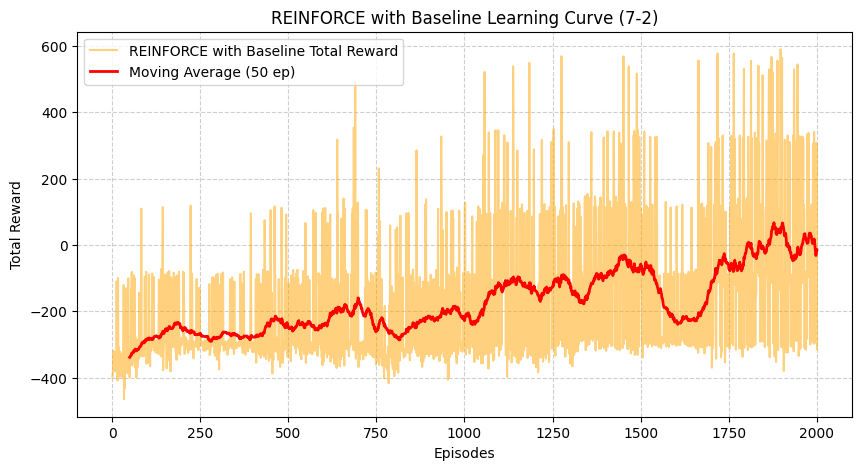

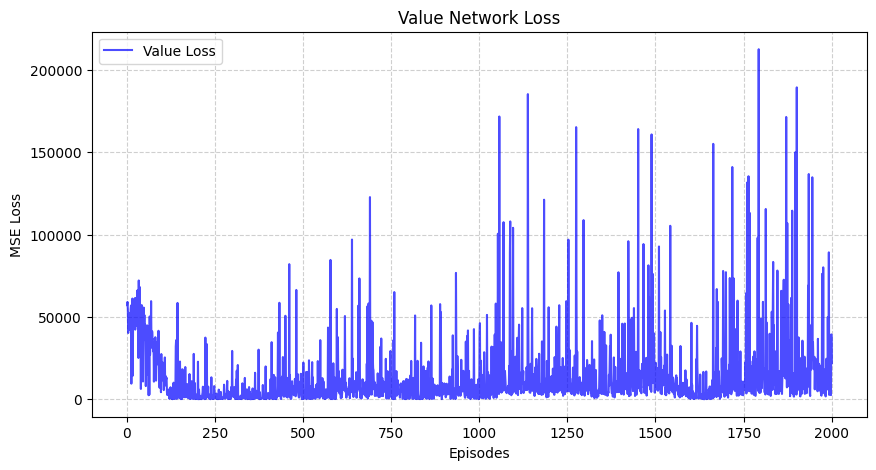

=== All 2000 Episodes ===
Idle           :   3312 (3.67%)
Add Dough      :  18588 (20.60%)
Add Cheese     :  45727 (50.68%)
Add Pepperoni  :   3970 (4.40%)
Add Mushroom   :  10108 (11.20%)
Add Olive      :   1810 (2.01%)
Serve          :   6715 (7.44%)

=== Last 100 Episodes ===
Idle           :    100 (2.25%)
Add Dough      :   1559 (35.11%)
Add Cheese     :   1632 (36.76%)
Add Pepperoni  :    208 (4.68%)
Add Mushroom   :    521 (11.73%)
Add Olive      :      8 (0.18%)
Serve          :    412 (9.28%)

=== Last 100 Episodes Performance ===
Average Reward: -19.57
Successful Orders: 139
Timed-out Orders: 261
Success Rate: 34.75%
Timeout Rate: 65.25%


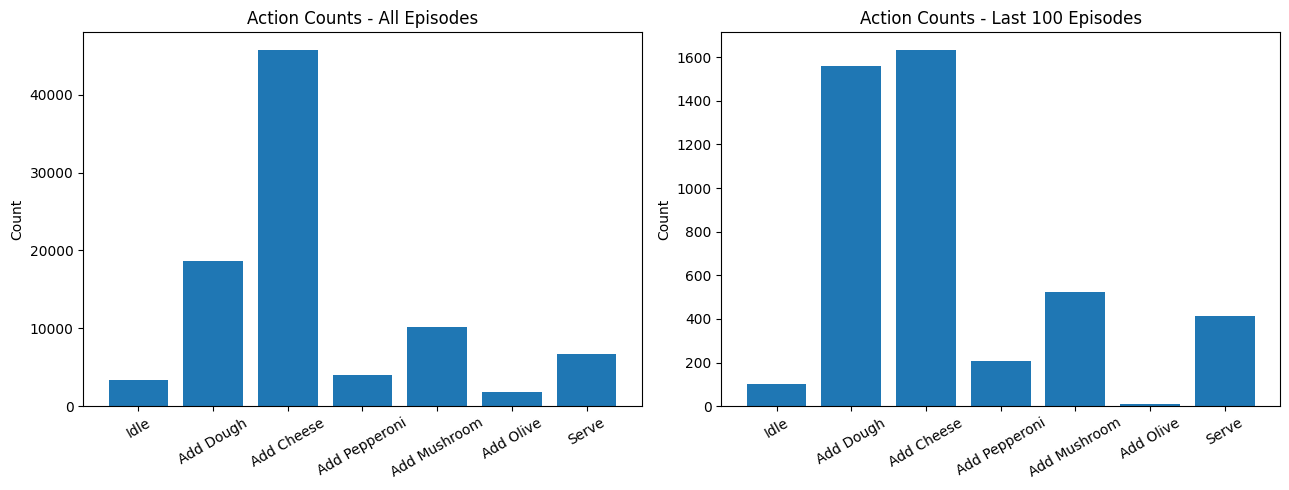

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4 # ⭐ 최대 주문 대기 수 4로 확장

        # ⭐ [d, c, p, m, o, m1, t1, m2, t2, m3, t3, m4, t4]
        # 재료 5개 + 주문 정보 8개 = 13차원
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        # Menu IDs can reach 2, so the upper bound is not 1 for all dimensions.
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array(
                            [1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1],
                            dtype=np.float32
            ),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(7)
        self.menus = {
            1: [1., 1., 0., 0., 0.],  # 치즈
            2: [1., 1., 1., 0., 0.],  # 페퍼로니
            3: [1., 1., 0., 1., 0.],  # 버섯
            4: [1., 1., 1., 1., 1.]   # 스페셜
        }

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []

        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = int(self.np_random.choice([1, 2, 3, 4]))
            timer = int(self.np_random.integers(36, 49)) # ⭐ 주문 타이머 24~36 → 36~48스텝 확장
            self.orders.append({
                'menu_id': menu_id,
                'timer': timer
            })

    def _get_obs(self):
        obs = list(self.counter)

        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 48.0) # ⭐ 타이머 최댓값 48 기준 정규화 (기존 36 → 48)
            else:
                obs.append(0.0)
                obs.append(0.0)

        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1:  # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0
            else:
                self.counter[0] = 1.0

        elif action == 2:  # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0:
                reward -= 2.0
            else:
                self.counter[1] = 1.0

        elif action == 3:  # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[2] = 1.0

        elif action == 4:  # Add Mushroom ⭐ 추가
            if self.counter[3] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[3] = 1.0

        elif action == 5:  # Add Olive ⭐ 추가
            if self.counter[4] == 1.0:
                reward -= 2.0
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0
            else:
                self.counter[4] = 1.0

        elif action == 6:  # Serve ⭐ 기존 4 → 6
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0  # ⭐ 정확한 피자 서빙 보상 (+150)
                    self.orders.pop(0)
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
                else:
                    reward -= 15.0
                    self.counter = np.zeros(5, dtype=np.float32)  # ⭐ 3 → 5
            else:
                reward -= 1.0

        # 2. Timer Update & Timeout Check
        orders_to_remove = []

        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}


# 2. Define Policy Network (same as original REINFORCE)
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)

        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x


# 3. Define Value Network (NEW: Baseline)
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x



# 4. REINFORCE with Baseline Training Function
# + Action Count & Success/Timeout Tracking

def train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
):
    reward_history = []
    policy_loss_history = []
    value_loss_history = []

    # Tracking
    action_history = []
    success_history = []
    timeout_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()

        log_probs = []
        states = []
        rewards = []

        # Count each action in this episode
        action_counts = np.zeros(7, dtype=np.int32)

        # Track orders completed / expired
        success_count = 0
        timeout_count = 0

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            probs = policy_net(state_tensor)
            m = torch.distributions.Categorical(probs)
            action = m.sample()

            action_id = action.item()

            # Record action
            action_counts[action_id] += 1

            log_probs.append(m.log_prob(action))
            states.append(state_tensor.squeeze(0))

            # Count orders before step
            orders_before = len(env.orders)
            first_order_before = (
                env.orders[0]['menu_id']
                if orders_before > 0 else None
            )
            counter_before = env.counter.copy()

            next_state, reward, terminated, truncated, info = env.step(
                action_id
            )

            # Detect successful serve
            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    success_count += 1

            # Infer expired orders from order count
            orders_after = len(env.orders)
            removed_orders = orders_before - orders_after

            if action_id == 6 and orders_before > 0:
                if np.array_equal(
                    counter_before,
                    env.menus[first_order_before]
                ):
                    removed_orders -= 1

            timeout_count += max(0, removed_orders)

            done = terminated or truncated
            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)

        reward_history.append(total_reward)
        action_history.append(action_counts)
        success_history.append(success_count)
        timeout_history.append(timeout_count)

        # Monte Carlo Returns
        returns = []
        G = 0.0

        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Value Network
        states_tensor = torch.stack(states)
        values = value_net(states_tensor).squeeze(-1)

        # Advantage
        advantages = returns - values.detach()

        # Policy Loss
        log_probs_tensor = torch.stack(log_probs).view(-1)
        policy_loss = -(log_probs_tensor * advantages).sum()

        # Value Loss
        value_loss = nn.functional.mse_loss(values, returns)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        value_optimizer.zero_grad()
        value_loss.backward()
        value_optimizer.step()

        policy_loss_history.append(policy_loss.item())
        value_loss_history.append(value_loss.item())

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(reward_history[-50:])

            print(
                    f"Episode [{episode+1}/{num_episodes}] | "
                    f"Total Reward: {total_reward:.2f} | "
                    f"Avg Reward (50): {avg_reward:.2f} | "
                    f"Success: {success_count} | "
                    f"Timeout: {timeout_count} | "
                    f"Value Loss: {value_loss.item():.4f}"
        )

    return (
        reward_history,
        policy_loss_history,
        value_loss_history,
        np.array(action_history),
        np.array(success_history),
        np.array(timeout_history)
    )



# 5. Execution

torch.manual_seed(123)

env = PizzaShopEnv()
env.reset(seed=123)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
value_net = ValueNetwork(state_dim)

policy_optimizer = optim.Adam(policy_net.parameters(), lr=0.001)
value_optimizer = optim.Adam(value_net.parameters(), lr=0.001)

(
    rewards_history,
    policy_losses,
    value_losses,
    action_history,
    success_history,
    timeout_history
) = train_reinforce_baseline(
    env,
    policy_net,
    value_net,
    policy_optimizer,
    value_optimizer,
    num_episodes=2000,
    gamma=0.99
)


# 6. Visualization: Total Reward
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rewards_history) + 1),
    rewards_history,
    label='REINFORCE with Baseline Total Reward',
    color='orange',
    alpha=0.5
)

window_size = 50

if len(rewards_history) >= window_size:
    moving_avg = np.convolve(
        rewards_history,
        np.ones(window_size) / window_size,
        mode='valid'
    )

    plt.plot(
        range(window_size, len(rewards_history) + 1),
        moving_avg,
        label=f'Moving Average ({window_size} ep)',
        color='red',
        linewidth=2
    )

plt.title('REINFORCE with Baseline Learning Curve (7-2)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 7. Visualization: Value Loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(value_losses) + 1),
    value_losses,
    label='Value Loss',
    color='blue',
    alpha=0.7
)

plt.title('Value Network Loss')
plt.xlabel('Episodes')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# 8. Action Selection Analysis

action_names = [
    'Idle',
    'Add Dough',
    'Add Cheese',
    'Add Pepperoni',
    'Add Mushroom',
    'Add Olive',
    'Serve'
]

total_counts = action_history.sum(axis=0)
last_100_counts = action_history[-100:].sum(axis=0)

total_steps = total_counts.sum()
last_100_steps = last_100_counts.sum()

print("=== All 2000 Episodes ===")
for name, count in zip(action_names, total_counts):
    percentage = 100 * count / max(total_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes ===")
for name, count in zip(action_names, last_100_counts):
    percentage = 100 * count / max(last_100_steps, 1)
    print(f"{name:15s}: {count:6d} ({percentage:.2f}%)")

print("\n=== Last 100 Episodes Performance ===")
print(f"Average Reward: {np.mean(rewards_history[-100:]):.2f}")
print(f"Successful Orders: {success_history[-100:].sum()}")
print(f"Timed-out Orders: {timeout_history[-100:].sum()}")

total_orders = (
    success_history[-100:].sum()
    + timeout_history[-100:].sum()
)

if total_orders > 0:
    print(
        f"Success Rate: "
        f"{100 * success_history[-100:].sum() / total_orders:.2f}%"
    )
    print(
        f"Timeout Rate: "
        f"{100 * timeout_history[-100:].sum() / total_orders:.2f}%"
    )

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(action_names, total_counts)
axes[0].set_title('Action Counts - All Episodes')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(action_names, last_100_counts)
axes[1].set_title('Action Counts - Last 100 Episodes')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
torch.save(
    policy_net.state_dict(),
    "reinforce_baseline_7_2.pth"
)

**현상**:

실험 6-2와 동일한 랜덤 시드(123) 및 환경 조건에서 주문 타이머를 24 ~ 36스텝에서 36 ~ 48스텝으로 증가시킨 결과, 최근 100에피소드 기준 평균 보상은 -121.84에서 -19.57로 증가하고 주문 성공률은 20.00%에서 34.75%로 개선되는 현상이 관찰됨.

학습 초반에는 이동 평균 보상이 약 -300점 부근에 머물렀으나, 학습이 진행되면서 점차 상승하여 후반부에는 일시적으로 양수 구간에 진입함. 다만 학습 후반에도 보상 변동이 크게 나타남.

최근 100에피소드에서 Idle 행동 비율은 2.25%로 낮게 나타났으나, Add Dough(35.11%)와 Add Cheese(36.76%)에 행동이 집중되었으며 주문 타임아웃 비율도 65.25%로 높게 나타남.

**원인 분석**:

실험 6-2와 비교하여 주문 타이머만 증가시켰으므로, 주문 처리에 사용할 수 있는 시간이 늘어난 것이 학습 성능 개선에 영향을 미친 것으로 판단됨.

주문 처리 시간이 증가하면서 여러 재료를 추가하고 서빙까지 완료할 기회가 확대되어, 기존보다 성공적인 주문 처리 경험을 더 많이 얻었을 가능성이 있음.

그러나 Add Olive 행동 비율은 0.18%에 불과하고 일부 재료에 행동이 집중되는 현상이 지속됨. 이는 다양한 메뉴에 필요한 재료 조합을 충분히 학습하지 못했을 가능성을 보여주며, 가치 함수 손실도 후반까지 큰 변동을 나타내 학습이 안정적으로 이루어지지 않았음을 시사함.

또한 동일한 타이머 조건에서도 실험 7-1(Seed 42)의 성공률은 43.50%, 실험 7-2(Seed 123)는 34.75%로 차이가 나타나 랜덤 시드에 따라 학습 결과가 달라질 수 있음을 확인함.

**결론 및 시사점**:

주문 타이머를 36~48스텝으로 확장한 결과, 시드 123에서도 평균 보상과 주문 성공률이 개선되어 주문 처리 시간의 확보가 복잡한 환경에서 학습 성능 향상에 긍정적인 영향을 미칠 수 있음을 확인함.

특히 실험 7-1과 7-2 모두 실험 6의 동일 시드 조건보다 높은 주문 성공률을 기록하여, 실험 6의 성능 저하에 주문 타이머 제약이 영향을 미쳤을 가능성을 뒷받침함.

다만 두 실험 모두 주문 타임아웃 비율이 50%를 초과하고 행동 편중 및 학습 변동성이 지속되었으므로, 타이머 확장만으로는 안정적인 주문 처리 정책을 충분히 학습하지 못했음을 확인함.

####
## 💡 REINFORCE with Baseline 종합 결론

REINFORCE with Baseline 알고리즘을 적용한 총 7차례의 실험을 통해 보상 조건과 주문 타이머, 환경 복잡도의 변화가 학습 성능에 미치는 영향을 분석함. 실험 6과 7에서는 랜덤 시드를 각각 42와 123으로 설정하여 학습 결과의 차이도 확인함.

초기 실험에서는 주문 처리에 성공하지 못하고 Idle 행동을 반복하는 경향이 나타났으나, 정답 서빙 보상을 +150으로 증가시킨 이후 주문 성공률이 65.00%까지 개선됨. 이후 최대 대기 주문 수를 4개로 확장하고 주문 타이머를 16~24스텝으로 조정한 실험 5에서는 주문 성공률 99.75%를 기록하며 높은 학습 성능을 보임.

반면 메뉴를 4개, 재료를 5개, 행동을 7개로 확장한 실험 6에서는 주문 성공률이 시드 42에서 8.00%, 시드 123에서 20.00%로 크게 저하됨. 이에 주문 타이머를 24 ~ 36스텝에서 36 ~ 48스텝으로 확장한 실험 7을 진행한 결과, 주문 성공률이 각각 43.50%, 34.75%로 개선됨.

이를 통해 복잡한 환경에서 주문 처리 시간의 제약이 학습 성능 저하에 영향을 미쳤을 가능성을 확인함. 다만 타이머 확장 이후에도 주문 성공률이 50%에 미치지 못하고, 일부 행동에 대한 편중과 가치 함수 손실의 큰 변동이 지속되어 안정적인 주문 처리 정책을 충분히 학습하지 못했음을 확인함.

따라서 이후 실험에서는 **Actor-Critic**을 적용하고, 동일한 최대 복잡도 환경과 36~48스텝의 주문 타이머 조건에서 평균 보상, 주문 성공률 및 학습 안정성을 비교하여 알고리즘별 성능 차이를 분석하고자 함.